# 15 · Explaining, auditing and questioning the model

**Question: why did the model make that prediction?**

Explainability does three jobs here:

1. **Global**: what generally drives predictions? (grouped permutation
   importance, TreeSHAP)
2. **Local**: why did Barcelona get 64% in *this* match? (SHAP for the exact
   model that made the prediction)
3. **Audit**: would the explanations reveal a leak if there were one? And
   what happened in the matches the model got most confidently wrong?

Explanations for every Barcelona fixture 2008/09-2020/21 are precomputed by
`barca explain` (package `barca.xai`) and served by the app.

In [1]:
import json
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca import config
from barca.data import store
from barca.models import data, metrics, production
from barca.xai import audit, errors, labels
from barca.xai import shap as xshap
from barca.visualization import style

warnings.filterwarnings("ignore")
style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(180)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)

MD = config.MODELS / "match_outcome"
glob = json.loads((MD / "global_explanations.json").read_text())
expl = pl.read_parquet(MD / "explanations_barca.parquet")
barca_pred = pl.read_parquet(MD / "predictions_barca.parquet")
ds = data.league_dataset(store.features("fixtures"))
print(f"explained Barcelona fixtures: {expl.height}")

explained Barcelona fixtures: 494


## 1. What drives the predictions? Permutation importance

For each holdout season, with the model trained before it: shuffle a
*group* of related features and measure how much log loss worsens.
Features are permuted in groups because many are near-duplicates (the
opponent's Elo, the Elo gap and the Elo expectation). Permuting one alone
would understate what the group knows.

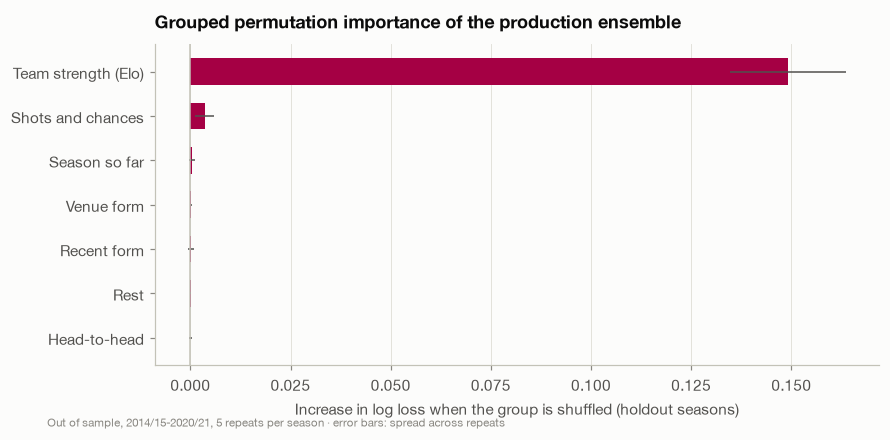

group,increase,std
str,f64,f64
"""Team strength (Elo)""",0.149,0.014
"""Shots and chances""",0.004,0.002
"""Season so far""",0.000,0.001
"""Venue form""",0.000,0.000
"""Recent form""",0.000,0.001
"""Rest""",0.000,0.000
"""Head-to-head""",0.000,0.000


In [2]:
perm = pl.DataFrame(glob["permutation"]).sort("increase", descending=True)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
p_ = perm.sort("increase")
ax.barh(p_["group"], p_["increase"], xerr=p_["std"], color=style.BARCA, height=0.6,
        error_kw={"ecolor": style.INK_2, "lw": 1})
ax.axvline(0, color=style.AXIS, lw=1)
ax.set_xlabel("Increase in log loss when the group is shuffled (holdout seasons)")
ax.set_title("Grouped permutation importance of the production ensemble")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
style.caption(ax, "Out of sample, 2014/15-2020/21, 5 repeats per season · error bars: spread across repeats")
style.savefig(fig, "15_permutation_importance")
plt.show()
perm

**Team strength (Elo) carries almost the whole model.** Shuffling it
raises log loss by about 0.15. Once Elo is known, every other group is worth
almost nothing on its own: shots and chances add a little (0.004), and recent
form, venue form, the season record, rest and head-to-head are within noise
of zero. That does not mean form is irrelevant. Elo already *is* a
form-weighted summary of every result, so the separate form features have
little left to add. This matches the baseline finding that Elo alone is
hard to beat.

## 2. TreeSHAP on the LightGBM member

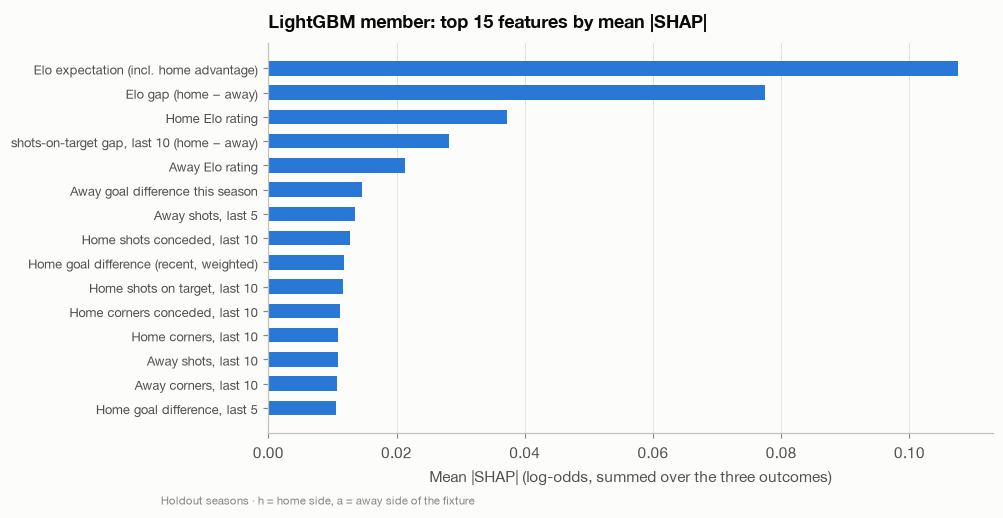

In [3]:
ts = pl.DataFrame(glob["tree_shap"]).head(15)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
t_ = ts.sort("mean_abs_shap")  # labels say which side of the fixture a feature describes
ax.barh(t_["label"], t_["mean_abs_shap"], color=style.OPPONENT, height=0.6)
ax.set_xlabel("Mean |SHAP| (log-odds, summed over the three outcomes)")
ax.set_title("LightGBM member: top 15 features by mean |SHAP|")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
style.caption(ax, "Holdout seasons · h = home side, a = away side of the fixture")
style.savefig(fig, "15_tree_shap")
plt.show()

The non-linear member leans on the same things: the Elo expectation and
the Elo gap first, then both sides' Elo ratings, the shots-on-target gap,
the season's goal difference and shot volumes. None of the top features is
a post-match quantity; the automated audit below checks that formally.

## 3. One prediction, explained

10 September 2016: Barcelona 1-2 Alavés at the Camp Nou, one of the most
surprising results of the era. What did the model think, and why?

In [4]:
fx = ds.meta.filter((pl.col("home") == "Barcelona") & (pl.col("away") == "Alavés") & (pl.col("season") == "2016/2017"))
fid = fx["fixture_id"][0]
row = expl.filter(pl.col("fixture_id") == fid).row(0, named=True)
contrib = pl.DataFrame(json.loads(row["contributions"]))
print(f"P(Barcelona win) = {row['p_win']:.2f}  (average prediction for a home win: {row['base_value']:.2f})")
contrib.select("label", "value", "shap")

P(Barcelona win) = 0.89  (average prediction for a home win: 0.49)


label,value,shap
str,f64,f64
"""Elo gap (Barcelona − opponent)""",314.889,0.222
"""Barcelona Elo rating""",1745.734,0.066
"""Barcelona's Elo expectation (incl. home advantage)""",0.907,0.053
"""Barcelona shots on target, last 10""",7.200,0.016
"""Opponent Elo rating""",1430.845,0.015
"""Barcelona shots on target conceded, last 10""",2.700,0.011
"""Opponent shots on target conceded, last 10""",3.300,-0.008
"""shots-on-target gap, last 10 (Barcelona − opponent)""",4.300,0.007
"""Barcelona goals conceded, last 10""",0.700,-0.007


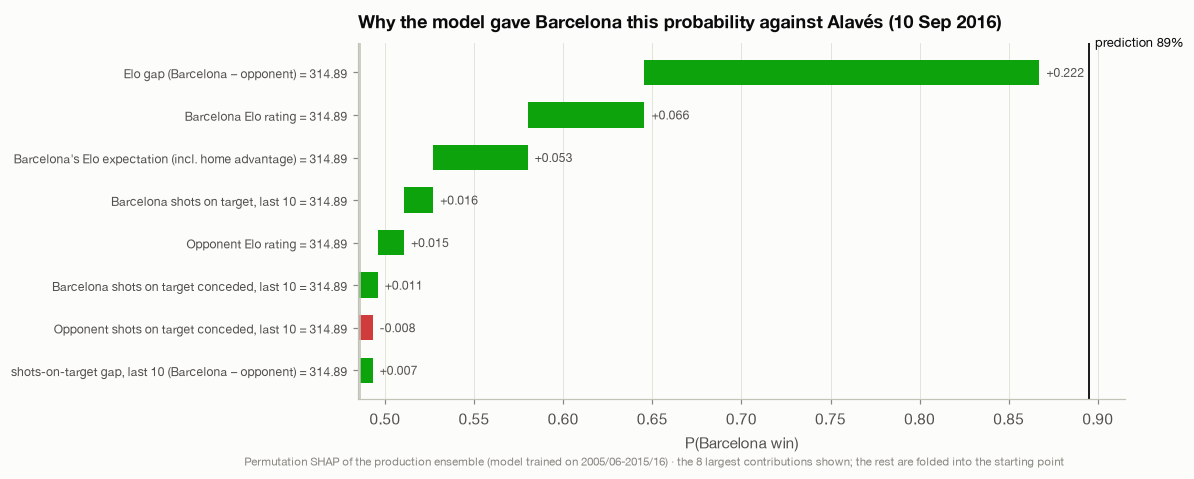

In [5]:
c = json.loads(row["contributions"])[:8][::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
start = row["base_value"] + sum(d["shap"] for d in json.loads(row["contributions"])[8:])
running = start
for i, d in enumerate(c):
    colour = style.RESULT_COLOURS["W"] if d["shap"] > 0 else style.RESULT_COLOURS["L"]
    ax.barh(i, d["shap"], left=running, color=colour, height=0.6)
    val = "" if d["value"] is None else f" = {d['value']:.2f}"
    ax.text(max(running, running + d["shap"]) + 0.004, i, f"{d['shap']:+.3f}", va="center", fontsize=8, color=style.INK_2)
    ax.set_yticks(range(len(c)), [f"{d['label']}{val}" for d in c], fontsize=8)
    running += d["shap"]
ax.axvline(row["base_value"], color=style.AXIS, lw=1)
ax.axvline(row["p_win"], color=style.INK, lw=1.2)
ax.annotate(f"prediction {row['p_win']:.0%}", (row["p_win"], len(c) - 0.4), xytext=(4, 0), textcoords="offset points",
            fontsize=8.5)
ax.set_xlabel("P(Barcelona win)")
ax.set_title("Why the model gave Barcelona this probability against Alavés (10 Sep 2016)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
style.caption(ax, "Permutation SHAP of the production ensemble (model trained on 2005/06-2015/16) · the 8 largest contributions shown; the rest are folded into the starting point")
style.savefig(fig, "15_waterfall_alaves")
plt.show()

The model made Barcelona heavy favourites, and the explanation shows
exactly why: a large Elo gap against a newly promoted side, home
advantage, and Barcelona's strong recent form. Everything the model could
see pointed one way. Section 6 looks at what it could not see.

## 4. How does opponent strength change the prediction? PDP and ICE

Partial dependence: take every Barcelona home match of 2020/21, set the
opponent's Elo to each value on a grid (rebuilding the Elo gap and
expectation consistently), and average the predicted P(Barcelona win).
ICE draws each match's own curve.

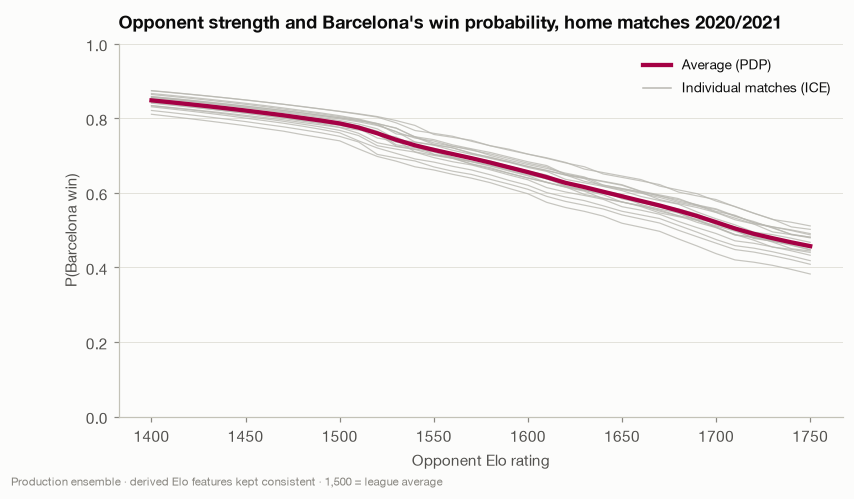

P(win) against a 1,450 side: 0.82 · against a 1,700 side: 0.52


In [6]:
pd_ = glob["pdp"]
grid = np.array(pd_["grid"])
curves = np.array(pd_["ice"])
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for curve in curves:
    ax.plot(grid, curve, color=style.NEUTRAL, lw=0.8, alpha=0.8)
ax.plot(grid, pd_["average"], color=style.BARCA, lw=2.8, label="Average (PDP)")
ax.plot([], [], color=style.NEUTRAL, lw=1, label="Individual matches (ICE)")
ax.set_xlabel("Opponent Elo rating")
ax.set_ylabel("P(Barcelona win)")
ax.set_ylim(0, 1)
ax.set_title(f"Opponent strength and Barcelona's win probability, home matches {pd_['season']}")
ax.legend(loc="upper right")
style.caption(ax, "Production ensemble · derived Elo features kept consistent · 1,500 = league average")
style.savefig(fig, "15_pdp_ice")
plt.show()
print(f"P(win) against a 1,450 side: {np.interp(1450, grid, pd_['average']):.2f} · "
      f"against a 1,700 side: {np.interp(1700, grid, pd_['average']):.2f}")

The relationship is smooth and monotone: every extra 100 Elo points of
opposition costs Barcelona a steady amount of win probability. The ICE
curves are nearly parallel. The *shape* of the effect is the same in every
match, and they differ only in level (Barcelona's own form going in). There is
no evidence of odd interactions in the non-linear member.

## 5. XAI as an audit: would a leak show up?

To show that the explanations would expose leakage, deliberately train a
**leaky** model: the same LightGBM, plus the match's own shots and shots on
target (known only after the final whistle).

In [7]:
fixtures = store.features("fixtures")
leak_cols = ["home_shots", "away_shots", "home_sot", "away_sot"]
res = store.results().select("date", "home", "away", *leak_cols)
leaky = fixtures.join(res, on=["date", "home", "away"], how="left")
train = leaky.filter(pl.col("season_start").is_between(2005, 2016))
test = leaky.filter(pl.col("season_start").is_between(2017, 2020))
feats = data.league_dataset(fixtures).features
ytr = train["result"].replace_strict({"H": 0, "D": 1, "A": 2}, return_dtype=pl.Int64).to_numpy()
yte = test["result"].replace_strict({"H": 0, "D": 1, "A": 2}, return_dtype=pl.Int64).to_numpy()
rows = []
for name, cols in [("honest", feats), ("leaky (+ same-match shots)", feats + leak_cols)]:
    Xtr = train.select(cols).cast(pl.Float64).to_pandas()
    Xte = test.select(cols).cast(pl.Float64).to_pandas()
    m = lgb.LGBMClassifier(objective="multiclass", n_estimators=300, learning_rate=0.03, num_leaves=8,
                           min_child_samples=60, colsample_bytree=0.5, verbose=-1, random_state=0).fit(Xtr, ytr)
    p = m.predict_proba(Xte)
    v = xshap.tree_shap(m, Xte)
    imp = dict(zip(cols, np.abs(v).mean(axis=(0, 2)), strict=True))
    top = sorted(imp, key=lambda f: -imp[f])[:5]
    rows.append({"model": name, "log_loss": metrics.log_loss(yte, p), "accuracy": metrics.accuracy(yte, p),
                 "top_5_features": ", ".join(top), "audit_flags": ", ".join(audit.check_top_features(imp)) or "none"})
pl.DataFrame(rows)

model,log_loss,accuracy,top_5_features,audit_flags
str,f64,f64,str,str
"""honest""",1.013,0.501,"""elo_diff, elo_expected, h_elo, sot_strength_diff_10, h_corne…","""none"""
"""leaky (+ same-match shots)""",0.877,0.595,"""home_sot, away_sot, home_shots, elo_diff, elo_expected""","""home_sot, away_sot, home_shots, away_shots"""


The leaky model looks spectacular: accuracy jumps from about 50% to 60% and
log loss collapses from 1.01 to 0.88, an improvement no honest football
model achieves (the betting market is about 0.95). Its
explanations give it away immediately: the top features are the match's own
shots on target, and the automated audit (`barca.xai.audit`, which checks
the most important features against a list of post-match columns) flags
them. The production model's audit result, computed on its TreeSHAP ranking:

In [8]:
print("production model audit flags:", glob["audit_flags"] or "none")

production model audit flags: none


**Explainability is part of validation, not decoration.** Together with
the future-scrambling test (notebook 09) and the feature-list test, the
audit gives three independent guards against leakage.

## 6. Error analysis: the confident misses

Barcelona fixtures where the model gave **≥ 70%** to an outcome that did
not happen, ordered by how surprised the model should have been
(−log P(actual result)):

In [9]:
confident = barca_pred.with_columns(pl.max_horizontal("p_win", "p_draw", "p_loss").alias("conf")).filter(pl.col("conf") >= 0.7)
print(f"fixtures where the model gave ≥ 70% to one outcome: {confident.height}; "
      f"misses it expected there (Σ 1 − confidence): {(1 - confident['conf']).sum():.1f}")
err = errors.high_confidence_errors(barca_pred, threshold=0.7)
ctx = errors.match_context(err, store.features("barca_matches"), store.features("team_match"), store.appearances())
print(f"{err.height} confident misses out of {barca_pred.height} fixtures ({err.height / barca_pred.height:.1%})")
ctx.select("date", "opponent", "is_home", "barca_goals", "opp_goals", "p_win", "barca_xg", "opp_xg", "barca_reds",
           "opp_reds").head(15)

fixtures where the model gave ≥ 70% to one outcome: 287; misses it expected there (Σ 1 − confidence): 53.0
51 confident misses out of 494 fixtures (10.3%)


date,opponent,is_home,barca_goals,opp_goals,p_win,barca_xg,opp_xg,barca_reds,opp_reds
date,str,bool,i16,i16,f64,f32,f32,u32,u32
2016-09-10,"""Alavés""",true,1,2,0.895,1.649,0.399,0,0
2010-09-11,"""Hércules""",true,0,2,0.855,1.580,1.769,0,0
2016-04-17,"""Valencia""",true,1,2,0.859,2.262,0.676,0,0
2014-11-01,"""Celta Vigo""",true,0,1,0.850,1.847,1.375,0,0
2015-02-21,"""Málaga""",true,0,1,0.859,0.759,1.419,0,0
2015-05-23,"""Deportivo La Coruña""",true,2,2,0.897,1.941,0.472,0,0
2021-04-29,"""Granada""",true,1,2,0.844,1.233,0.536,0,0
2018-11-11,"""Real Betis""",true,3,4,0.852,4.173,2.022,1,0
2014-05-03,"""Getafe""",true,2,2,0.897,1.550,0.573,0,0


What went on in these matches? Three questions, answered from the event
data the outcome model does not use:

1. **Did Barcelona actually play badly?** Compare xG: if Barcelona created
   more than the opponent, the model's view of the match was right and the
   result turned on finishing or goalkeeping.
2. **Was there a red card?**
3. **Were regular starters missing?** Messi's absence from the starting XI
   is the obvious test.

In [10]:
known = ctx.filter(pl.col("barca_xg").is_not_null())
messi_absent = known.filter(pl.col("starters").is_not_null()).with_columns(
    (~pl.col("starters").list.contains("Lionel Messi")).alias("messi_not_starting")
)
summary = {
    "confident misses with event data": known.height,
    "Barcelona out-created the opponent (xG)": int((known["barca_xg"] > known["opp_xg"]).sum()),
    "Barcelona xG ≥ 1.5 yet did not win": int((known["barca_xg"] >= 1.5).sum()),
    "a Barcelona player sent off": int((known["barca_reds"] > 0).sum()),
    "Messi not in the starting XI": int(messi_absent["messi_not_starting"].sum()),
}
summary

{'confident misses with event data': 45,
 'Barcelona out-created the opponent (xG)': 31,
 'Barcelona xG ≥ 1.5 yet did not win': 19,
 'a Barcelona player sent off': 9,
 'Messi not in the starting XI': 5}

In [11]:
all_ctx = errors.match_context(barca_pred, store.features("barca_matches"), store.features("team_match"),
                               store.appearances()).filter(pl.col("barca_xg").is_not_null())
base = {
    "Barcelona out-created the opponent (xG)": float((all_ctx["barca_xg"] > all_ctx["opp_xg"]).mean()),
    "a Barcelona player sent off": float((all_ctx["barca_reds"] > 0).mean()),
    "Messi not in the starting XI": float(
        (~all_ctx.filter(pl.col("starters").is_not_null())["starters"].list.contains("Lionel Messi")).mean()),
}
pl.DataFrame([
    {"situation": k, "share of confident misses": summary[k] / known.height, "share of all matches": v}
    for k, v in base.items()
])

situation,share of confident misses,share of all matches
str,f64,f64
"""Barcelona out-created the opponent (xG)""",0.689,0.841
"""a Barcelona player sent off""",0.200,0.069
"""Messi not in the starting XI""",0.111,0.089


First, these misses are **expected**. Among the fixtures where the model
was at least 70% sure, the probabilities themselves imply roughly the
number of misses that happened (printed above). A 75% favourite should fail
to win one match in four, and these are those matches.

Second, **most were good performances with bad outcomes**. In about two
thirds of the confident misses Barcelona still out-created the opponent,
and in 19 of them Barcelona produced 1.5+ xG and still did not win. The
pre-match picture ("a much stronger team") was usually confirmed by the
match itself, and the result turned on finishing, goalkeeping or a single
moment. That share is lower than Barcelona's usual 84%, so a genuinely poor
performance is part of the story in the rest.

Third, **red cards are over-represented**: a Barcelona player was sent off
in about one in five confident misses, several times the usual rate. A
red card is in-match information no pre-match model can have. Messi's
absence from the XI, by contrast, is *not* over-represented here: rotation
around him was usually well judged. Absent key players remain a blind spot
in principle, and the obvious next feature is **expected lineup
strength**, which the starting-XI model (notebook 16) makes possible.

## Findings

1. **Elo dominates** the model's reasoning, with form and season record
   second: consistent across permutation importance, TreeSHAP and local
   explanations.
2. **Local explanations sum exactly** to each prediction (SHAP's efficiency
   property) and are computed with the model that made it.
3. **Opponent strength acts smoothly and consistently** (PDP/ICE).
4. **XAI catches leakage**: a deliberately leaky model is flagged by its own
   explanations and by the automated audit. The production model passes.
5. **The confident misses are the ones the model expected to have**, most
   were good performances with bad outcomes, and red cards (in-match
   information) are heavily over-represented among them.

Next: predicting the starting XI (`16_lineup_prediction`).